# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Qaulannisa Andaru Susilo
- NIM   : 241011402064
- Kelas : Reg B / 05TPLM001

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 64

In [ ]:
# Salin fungsi train_test_split dari materi di sini
# train_test_split:
# this function splits the dataset into training and testing sets based on the specified test size and random state.
# the method takes in the features (X), target variable (y), test size, and random state as inputs and returns the training and testing sets for both features and target variable.
# example usage:
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7)

def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40

Bentuk X: (40, 1)
Bentuk y: (40,)


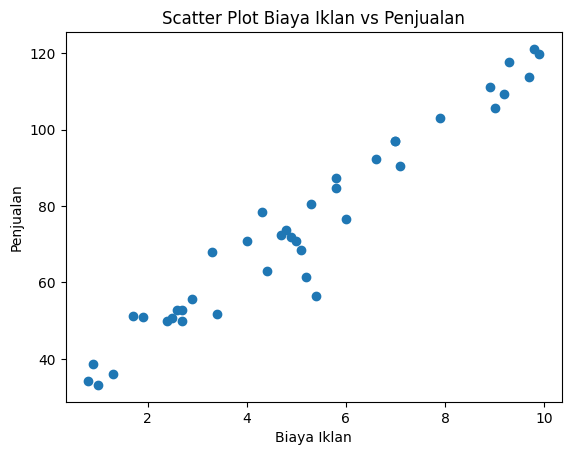

In [ ]:
# Jawaban A1

import pandas as pd
import matplotlib.pyplot as plt

# 1. Membaca data dan menampilkan 5 data pertama serta jumlah baris
df = pd.read_csv('Ads_Data.csv')

print("5 data pertama:")
print(df.head())

print("\nJumlah baris data:", len(df))

# 2. Memisahkan variabel X dan y
X = df[['BiayaIklan']].values
y = df['Penjualan'].values

print("\nBentuk X:", X.shape)
print("Bentuk y:", y.shape)

# 3. Membuat scatter plot BiayaIklan vs Penjualan
plt.scatter(X, y)

plt.title('Scatter Plot Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan')
plt.ylabel('Penjualan')
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
# Jawaban A2

# Buat fungsi train_test_split
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = len(X)
    shuffled_indices = np.random.permutation(n_samples)
    test_size = int(n_samples * test_size)
    test_indices = shuffled_indices[:test_size]
    train_indices = shuffled_indices[test_size:]
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

# Split data untuk Ads
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Shape X_train:", X_train_a.shape)
print("Shape X_test :", X_test_a.shape)
print("Shape y_train:", y_train_a.shape)
print("Shape y_test :", y_test_a.shape)


Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# Jawaban A3

# Menghitung parameter model menggunakan Normal Equation
X_b = np.c_[np.ones((X_train_a.shape[0], 1)), X_train_a]

theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y_train_a

# Mengambil nilai intercept (b) dan koefisien (m)
b = theta[0]
m = theta[1]

print("Intercept (b):", b)
print("Koefisien (m):", m)

# Persamaan garis regresi
print(f"Persamaan regresi: ŷ = {b:.4f} + {m:.4f}X")


Intercept (b): 28.975460723335694
Koefisien (m): 9.136546878599397
Persamaan regresi: ŷ = 28.9755 + 9.1365X


**Jawaban A3 (interpretasi):**

Nilai intercept (b) menunjukkan perkiraan penjualan ketika biaya iklan bernilai nol. Sementara itu, koefisien (m) menunjukkan perubahan penjualan untuk setiap kenaikan satu satuan biaya iklan. Jika biaya iklan diukur dalam juta rupiah, nilai koefisien dikalikan satu juta rupiah menunjukkan perubahan penjualan yang diprediksi oleh model.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
# Jawaban A4

# Jawaban A4

# Fungsi evaluasi model
def evaluasi_model(y_actual, y_pred):
    mae = np.mean(np.abs(y_actual - y_pred))
    mse = np.mean((y_actual - y_pred) ** 2)
    rmse = np.sqrt(mse)

    ss_res = np.sum((y_actual - y_pred) ** 2)
    ss_tot = np.sum((y_actual - np.mean(y_actual)) ** 2)
    r2 = 1 - (ss_res / ss_tot)

    return mae, mse, rmse, r2


# Prediksi data training dan testing
y_train_pred = b + m * X_train_a.ravel()
y_test_pred = b + m * X_test_a.ravel()

# Menghitung evaluasi
mae_train, mse_train, rmse_train, r2_train = evaluasi_model(
    y_train_a, y_train_pred
)

mae_test, mse_test, rmse_test, r2_test = evaluasi_model(
    y_test_a, y_test_pred
)

# Menampilkan hasil dalam satu tabel
hasil_evaluasi = pd.DataFrame({
    'Data': ['Training', 'Testing'],
    'MAE': [mae_train, mae_test],
    'MSE': [mse_train, mse_test],
    'RMSE': [rmse_train, rmse_test],
    'R2': [r2_train, r2_test]
})

print(hasil_evaluasi.round(4))


       Data     MAE      MSE    RMSE      R2
0  Training  4.0100  26.3405  5.1323  0.9594
1   Testing  6.1746  78.7421  8.8737  0.8229


**Jawaban A4 (analisis):**

MAE menunjukkan rata-rata selisih absolut antara hasil prediksi dan nilai aktual, sedangkan MSE menghitung rata-rata kuadrat kesalahan prediksi. RMSE merupakan akar dari MSE dan menunjukkan besarnya kesalahan prediksi dalam satuan yang sama dengan variabel penjualan. Semakin kecil nilai MAE, MSE, dan RMSE, semakin dekat hasil prediksi dengan nilai aktual.

Nilai R² menunjukkan seberapa baik model menjelaskan variasi data penjualan. Nilai R² yang mendekati 1 menunjukkan kemampuan penjelasan model yang lebih baik, sedangkan nilai yang mendekati 0 menunjukkan kemampuan penjelasan yang terbatas. Model dapat dikatakan cukup baik apabila memiliki kesalahan prediksi yang relatif kecil dan nilai R² yang baik pada data testing.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

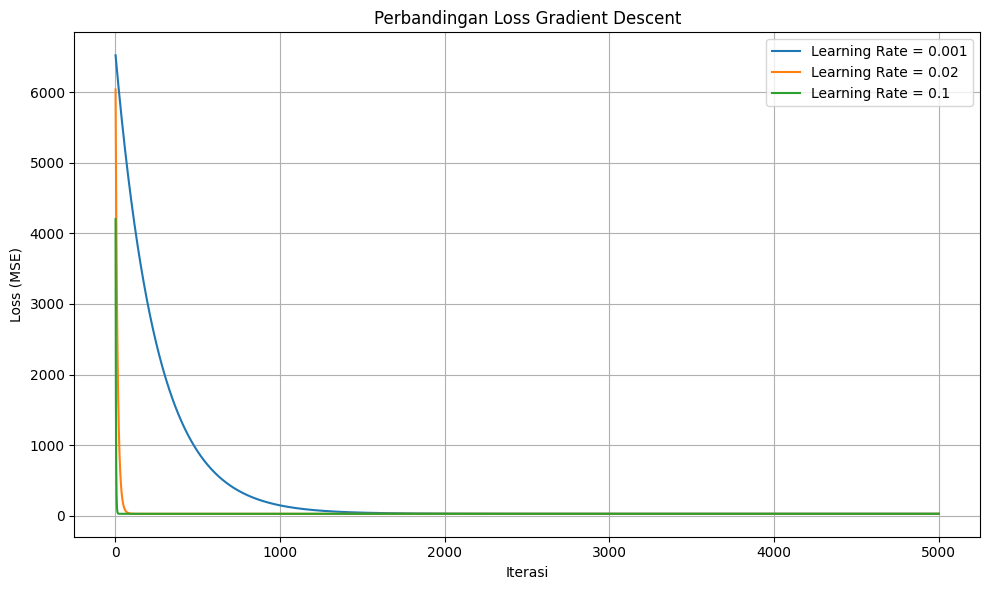

Grafik berhasil dibuat.


In [ ]:
# Jawaban A5


# A5 - Grafik Gradient Descent yang lebih jelas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Gunakan data training yang sudah ada
X_raw = X_train_a.astype(float)
y_data = y_train_a.astype(float).ravel()

# Normalisasi fitur agar Gradient Descent stabil
x_mean = X_raw.mean()
x_std = X_raw.std()
X_scaled = (X_raw - x_mean) / x_std

# Tambahkan kolom intercept
X_b = np.c_[np.ones(len(X_scaled)), X_scaled]

learning_rates = [0.001, 0.02, 0.1]
plt.figure(figsize=(10, 6))

for lr in learning_rates:
    theta = np.zeros(2)
    losses = []

    for i in range(5000):
        pred = X_b @ theta
        error = pred - y_data
        gradient = (2 / len(y_data)) * (X_b.T @ error)
        theta -= lr * gradient

        loss = np.mean((y_data - X_b @ theta) ** 2)
        losses.append(loss)

    plt.plot(
        range(1, 5001),
        losses,
        label=f'Learning Rate = {lr}'
    )

plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE)')
plt.title('Perbandingan Loss Gradient Descent')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Grafik berhasil dibuat.")


**Jawaban A5 (analisis):**

Pada learning rate 0.001, proses penurunan loss berlangsung relatif lambat karena perubahan parameter pada setiap iterasi kecil. Learning rate 0.02 memungkinkan loss menurun lebih cepat dan mencapai kondisi yang lebih stabil. Sementara itu, learning rate 0.1 pada percobaan awal mengalami *overflow* setelah 192 iterasi karena pembaruan parameter terlalu besar, sehingga nilai loss menjadi tidak terhingga.

Perbedaan tersebut terjadi karena learning rate menentukan besar langkah yang digunakan untuk memperbarui parameter model pada Gradient Descent. Nilai yang terlalu kecil membuat proses pembelajaran lambat, sedangkan nilai yang terlalu besar dapat menyebabkan model tidak stabil atau gagal konvergen. Normalisasi fitur dapat membantu menstabilkan proses pembelajaran, sehingga learning rate yang lebih besar dapat diuji tanpa langsung menyebabkan overflow.

Hasil Gradient Descent perlu dibandingkan dengan metode Normal Equation pada Soal A3. Jika proses optimasi telah konvergen, parameter model Gradient Descent diharapkan mendekati hasil Normal Equation. Dengan demikian, pemilihan learning rate yang tepat penting untuk memperoleh model dengan loss rendah dan proses pembelajaran yang stabil.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

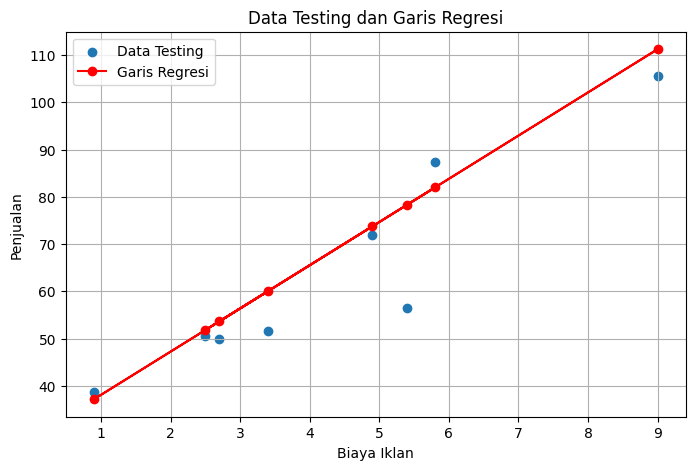

Hasil Prediksi:
   Biaya Iklan (juta Rp)  Prediksi Penjualan
0                    4.5             70.0899
1                    7.0             92.9313
2                   12.0            138.6140


In [ ]:
# Jawaban A6

# Jawaban A6 - Visualisasi & Prediksi

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Scatter plot data testing dan garis regresi A3
y_test_pred = b + m * X_test_a.ravel()

plt.figure(figsize=(8, 5))
plt.scatter(X_test_a.ravel(), y_test_a, label='Data Testing')
plt.plot(X_test_a.ravel(), y_test_pred, color='red',
         marker='o', label='Garis Regresi')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan')
plt.ylabel('Penjualan')
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi penjualan untuk biaya iklan 4.5, 7, dan 12 juta
biaya_iklan = np.array([[4.5], [7], [12]])
prediksi = b + m * biaya_iklan.ravel()

hasil_prediksi = pd.DataFrame({
    'Biaya Iklan (juta Rp)': biaya_iklan.ravel(),
    'Prediksi Penjualan': prediksi
})

print("Hasil Prediksi:")
print(hasil_prediksi.round(4))


**Jawaban A6 (analisis):**
Grafik scatter menunjukkan persebaran data testing, sedangkan garis regresi menggambarkan hubungan linear yang dipelajari model antara biaya iklan dan penjualan. Prediksi untuk biaya iklan sebesar Rp4,5 juta, Rp7 juta, dan Rp12 juta dihitung menggunakan persamaan regresi yang diperoleh pada Soal A3.

Prediksi untuk biaya iklan Rp4,5 juta dan Rp7 juta relatif lebih dapat dipercaya apabila nilainya masih berada dalam rentang data biaya iklan yang digunakan untuk melatih model. Sebaliknya, prediksi untuk biaya iklan Rp12 juta merupakan ekstrapolasi apabila nilai tersebut berada di luar rentang data training. Hasil ekstrapolasi perlu ditafsirkan secara hati-hati karena hubungan linear yang dipelajari model belum tentu tetap berlaku di luar rentang pengamatan.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah email Spam dan Bukan Spam:
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64

Shape X: (60, 2)
Shape y: (60,)


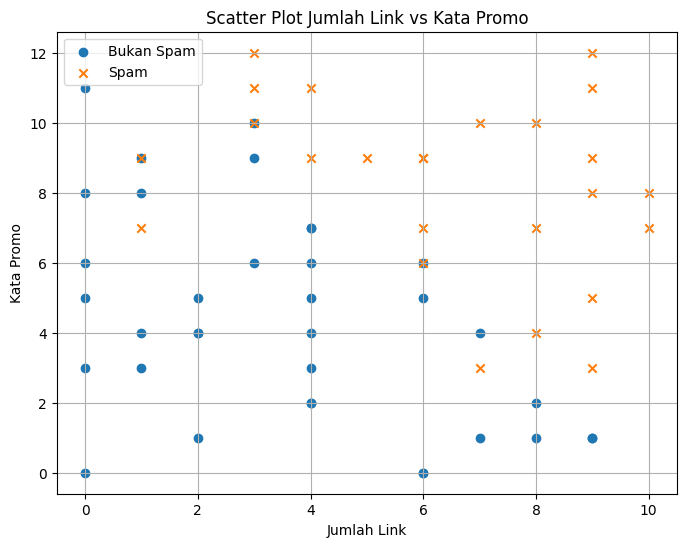

In [ ]:
# Jawaban B1

import pandas as pd
import matplotlib.pyplot as plt

# 1. Membaca dataset dan menampilkan 5 data pertama
df_email = pd.read_csv('Email_Data.csv')

print("5 data pertama:")
print(df_email.head())

# Menghitung jumlah email Spam dan Bukan Spam
print("\nJumlah email Spam dan Bukan Spam:")
print(df_email['Spam'].value_counts().rename(
    index={0: 'Bukan Spam', 1: 'Spam'}
))

# 2. Memisahkan variabel X dan y
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

print("\nShape X:", X_email.shape)
print("Shape y:", y_email.shape)

# 3. Scatter plot dengan warna berbeda untuk Spam dan Bukan Spam
plt.figure(figsize=(8, 6))

plt.scatter(
    df_email.loc[df_email['Spam'] == 0, 'JumlahLink'],
    df_email.loc[df_email['Spam'] == 0, 'KataPromo'],
    label='Bukan Spam',
    marker='o'
)

plt.scatter(
    df_email.loc[df_email['Spam'] == 1, 'JumlahLink'],
    df_email.loc[df_email['Spam'] == 1, 'KataPromo'],
    label='Spam',
    marker='x'
)

plt.title('Scatter Plot Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape X_train: (45, 2)
Shape X_test : (15, 2)
Shape y_train: (45,)
Shape y_test : (15,)

Intercept (b): -10.932968786487713
Koefisien m1 (JumlahLink): 1.0162754405651646
Koefisien m2 (KataPromo): 0.8476513669451748

P(Spam) = sigmoid(-10.9330 + (1.0163 * JumlahLink) + (0.8477 * KataPromo))


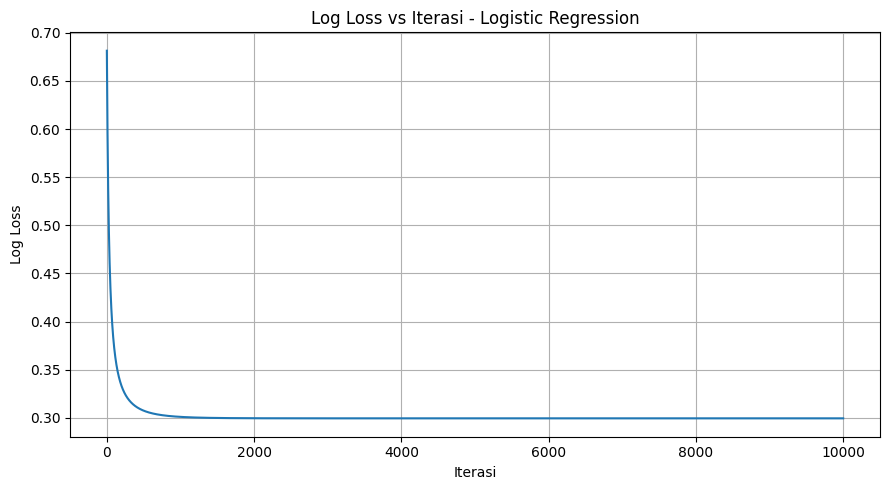


Log loss awal: 0.681444
Log loss akhir: 0.299491


In [ ]:
# Jawaban B2

# Jawaban B2 - Split Data & Training Logistic Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split as sklearn_split

# 1. Membaca data dan membagi training-testing
df_email = pd.read_csv('Email_Data.csv')

X_email = df_email[['JumlahLink', 'KataPromo']].values.astype(float)
y_email = df_email['Spam'].values.astype(float)

RANDOM_STATE = 64

X_train_b, X_test_b, y_train_b, y_test_b = sklearn_split(
    X_email, y_email,
    test_size=0.25,
    random_state=RANDOM_STATE
)

print("Shape X_train:", X_train_b.shape)
print("Shape X_test :", X_test_b.shape)
print("Shape y_train:", y_train_b.shape)
print("Shape y_test :", y_test_b.shape)


# 2. Normalisasi fitur agar Gradient Descent stabil
x_mean = X_train_b.mean(axis=0)
x_std = X_train_b.std(axis=0)
x_std[x_std == 0] = 1

X_train_scaled = (X_train_b - x_mean) / x_std

# Tambahkan kolom intercept
X_b = np.c_[np.ones(len(X_train_scaled)), X_train_scaled]


# Fungsi sigmoid
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# 3. Training Logistic Regression dengan Gradient Descent
learning_rate = 0.1
n_iterations = 10000

theta = np.zeros(X_b.shape[1])
log_loss_history = []

for i in range(n_iterations):
    z = X_b @ theta
    y_pred = sigmoid(z)

    gradient = (X_b.T @ (y_pred - y_train_b)) / len(y_train_b)
    theta -= learning_rate * gradient

    # Menghitung log loss
    p = np.clip(sigmoid(X_b @ theta), 1e-15, 1 - 1e-15)

    loss = -np.mean(
        y_train_b * np.log(p)
        + (1 - y_train_b) * np.log(1 - p)
    )

    log_loss_history.append(loss)


# 4. Mengembalikan koefisien ke skala fitur asli
b = theta[0] - np.sum(theta[1:] * x_mean / x_std)
koefisien = theta[1:] / x_std

m1 = koefisien[0]
m2 = koefisien[1]

print("\nIntercept (b):", b)
print("Koefisien m1 (JumlahLink):", m1)
print("Koefisien m2 (KataPromo):", m2)

print(
    f"\nP(Spam) = sigmoid("
    f"{b:.4f} + ({m1:.4f} * JumlahLink)"
    f" + ({m2:.4f} * KataPromo))"
)


# 5. Grafik log loss vs iterasi
plt.figure(figsize=(9, 5))
plt.plot(range(1, n_iterations + 1), log_loss_history)
plt.title('Log Loss vs Iterasi - Logistic Regression')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nLog loss awal:", round(log_loss_history[0], 6))
print("Log loss akhir:", round(log_loss_history[-1], 6))


**Jawaban B2 (analisis):**
Dataset dibagi menjadi 75% data training dan 25% data testing dengan menggunakan `RANDOM_STATE = 64` agar pembagian data konsisten. Model Logistic Regression dilatih menggunakan metode Gradient Descent dengan learning rate 0,1 dan 10.000 iterasi. Normalisasi fitur dilakukan untuk membantu menjaga kestabilan proses pembelajaran karena kedua fitur memiliki rentang nilai yang berbeda.

Nilai intercept (b) menunjukkan konstanta pada persamaan Logistic Regression, sedangkan koefisien m1 dan m2 menunjukkan pengaruh JumlahLink dan KataPromo terhadap nilai log-odds email termasuk kategori spam. Probabilitas email dikategorikan sebagai spam dihitung menggunakan fungsi sigmoid dari persamaan tersebut.

Grafik log loss digunakan untuk mengamati proses pembelajaran model. Jika log loss menurun dan kemudian cenderung stabil, proses optimasi menunjukkan konvergensi. Sebaliknya, jika log loss meningkat atau berfluktuasi secara tidak stabil, learning rate atau pengaturan model perlu dievaluasi kembali.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
# Jawaban B3

# 1. Prediksi data testing menggunakan model B2
X_test_scaled = (X_test_b - x_mean) / x_std
X_test_bias = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]

prob_test = sigmoid(X_test_bias @ theta)
y_pred = (prob_test >= 0.5).astype(int)

# 2. Menghitung confusion matrix secara manual
TP = np.sum((y_test_b == 1) & (y_pred == 1))
TN = np.sum((y_test_b == 0) & (y_pred == 0))
FP = np.sum((y_test_b == 0) & (y_pred == 1))
FN = np.sum((y_test_b == 1) & (y_pred == 0))

# 3. Menghitung metrik evaluasi
accuracy = (TP + TN) / len(y_test_b)

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

# 4. Menampilkan hasil
conf_matrix = pd.DataFrame(
    [[TN, FP], [FN, TP]],
    index=['Aktual Bukan Spam', 'Aktual Spam'],
    columns=['Prediksi Bukan Spam', 'Prediksi Spam']
)

print("Confusion Matrix:")
print(conf_matrix)

print("\nAccuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1_score, 4))


Confusion Matrix:
                   Prediksi Bukan Spam  Prediksi Spam
Aktual Bukan Spam                    9              0
Aktual Spam                          1              5

Accuracy : 0.9333
Precision: 1.0
Recall   : 0.8333
F1-score : 0.9091


**Jawaban B3 (analisis):**
Accuracy menunjukkan proporsi seluruh email yang berhasil diklasifikasikan dengan benar. Precision mengukur ketepatan prediksi email spam, sedangkan recall mengukur kemampuan model menemukan email yang benar-benar spam. F1-score merupakan rata-rata harmonis antara precision dan recall sehingga dapat digunakan untuk menilai keseimbangan keduanya.

False Positive (FP) terjadi ketika email bukan spam justru dikategorikan sebagai spam. Kesalahan ini dapat merugikan pengguna karena email penting berisiko masuk ke folder spam. Sementara itu, False Negative (FN) terjadi ketika email spam dikategorikan sebagai bukan spam sehingga pesan yang tidak diinginkan dapat masuk ke kotak masuk. Tingkat kerugian dari kedua kesalahan bergantung pada konteks penggunaan, tetapi dalam sistem penyaringan spam, FN dapat meningkatkan risiko pengguna terpapar pesan penipuan atau tautan berbahaya.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Persamaan decision boundary:
KataPromo = -(-10.9330 + (1.0163 * JumlahLink)) / 0.8477


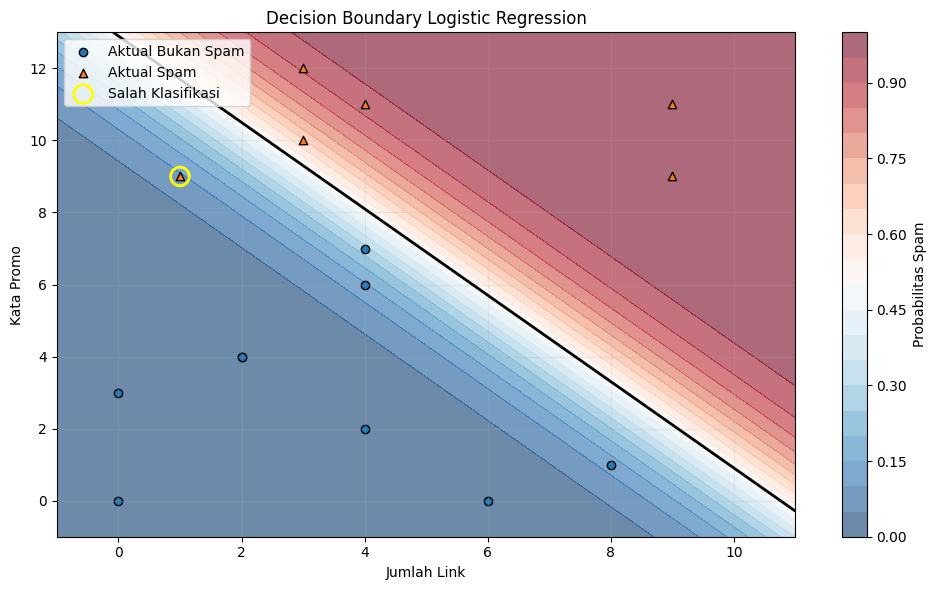


Jumlah data salah klasifikasi: 1
Indeks data salah klasifikasi: [0]


In [ ]:
# Jawaban B4

# Jawaban B4 - Decision Boundary

import numpy as np
import matplotlib.pyplot as plt

# Prediksi probabilitas data testing
X_test_scaled = (X_test_b - x_mean) / x_std
X_test_bias = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]
prob_test = sigmoid(X_test_bias @ theta)
y_pred = (prob_test >= 0.5).astype(int)

# Menampilkan persamaan decision boundary
print("Persamaan decision boundary:")
print(f"KataPromo = -({b:.4f} + ({m1:.4f} * JumlahLink)) / {m2:.4f}")

# Membuat grid untuk background probabilitas
x_min = X_email[:, 0].min() - 1
x_max = X_email[:, 0].max() + 1
y_min = X_email[:, 1].min() - 1
y_max = X_email[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = (grid - x_mean) / x_std
grid_bias = np.c_[np.ones(len(grid_scaled)), grid_scaled]

prob_grid = sigmoid(grid_bias @ theta).reshape(xx.shape)

# Visualisasi background probabilitas dan decision boundary
plt.figure(figsize=(10, 6))

contour = plt.contourf(
    xx, yy, prob_grid,
    levels=20, cmap='RdBu_r', alpha=0.6
)
plt.colorbar(contour, label='Probabilitas Spam')

boundary = plt.contour(
    xx, yy, prob_grid,
    levels=[0.5], colors='black', linewidths=2
)

# Data testing: warna sesuai kelas aktual
plt.scatter(
    X_test_b[y_test_b == 0, 0],
    X_test_b[y_test_b == 0, 1],
    marker='o', edgecolors='black',
    label='Aktual Bukan Spam'
)

plt.scatter(
    X_test_b[y_test_b == 1, 0],
    X_test_b[y_test_b == 1, 1],
    marker='^', edgecolors='black',
    label='Aktual Spam'
)

# Menandai data yang salah diklasifikasikan
salah = y_pred != y_test_b

plt.scatter(
    X_test_b[salah, 0],
    X_test_b[salah, 1],
    s=180, facecolors='none',
    edgecolors='yellow', linewidths=2,
    label='Salah Klasifikasi'
)

plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.title('Decision Boundary Logistic Regression')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("\nJumlah data salah klasifikasi:", np.sum(salah))
print("Indeks data salah klasifikasi:", np.where(salah)[0])


**Jawaban B4 (analisis):**
Decision boundary merupakan batas yang memisahkan prediksi email Spam dan Bukan Spam berdasarkan probabilitas sebesar 0,5. Pada model Logistic Regression, batas tersebut diperoleh dari persamaan \(b + m_1x_1 + m_2x_2 = 0\), dengan \(x_1\) sebagai JumlahLink dan \(x_2\) sebagai KataPromo.

Background probabilitas pada grafik menunjukkan tingkat kemungkinan suatu email dikategorikan sebagai spam. Titik data testing yang berada pada wilayah prediksi berbeda dari kelas aktualnya merupakan kesalahan klasifikasi. Kesalahan tersebut ditandai dengan lingkaran kuning pada grafik. Semakin baik pemisahan antara kedua kelas, semakin baik kemampuan model dalam membedakan email Spam dan Bukan Spam.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [ ]:
# Jawaban B5

# Jawaban B5 - Eksperimen Threshold

import numpy as np
import pandas as pd

# Menghitung probabilitas spam pada data testing
X_test_scaled = (X_test_b - x_mean) / x_std
X_test_bias = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]

predict_proba = sigmoid(X_test_bias @ theta)

# Fungsi evaluasi confusion matrix, precision, dan recall
hasil_threshold = []

for threshold in [0.3, 0.5, 0.7]:
    y_pred_threshold = (predict_proba >= threshold).astype(int)

    TP = np.sum((y_test_b == 1) & (y_pred_threshold == 1))
    TN = np.sum((y_test_b == 0) & (y_pred_threshold == 0))
    FP = np.sum((y_test_b == 0) & (y_pred_threshold == 1))
    FN = np.sum((y_test_b == 1) & (y_pred_threshold == 0))

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    hasil_threshold.append({
        'Threshold': threshold,
        'TN': TN,
        'FP': FP,
        'FN': FN,
        'TP': TP,
        'Precision': round(precision, 4),
        'Recall': round(recall, 4)
    })

tabel_threshold = pd.DataFrame(hasil_threshold)

print("Hasil Evaluasi Setiap Threshold:")
print(tabel_threshold.to_string(index=False))


Hasil Evaluasi Setiap Threshold:
 Threshold  TN  FP  FN  TP  Precision  Recall
       0.3   9   0   1   5        1.0  0.8333
       0.5   9   0   1   5        1.0  0.8333
       0.7   9   0   2   4        1.0  0.6667


**Jawaban B5 (analisis):**
Threshold menentukan batas probabilitas yang digunakan untuk mengklasifikasikan email sebagai spam. Pada threshold 0,3, model lebih mudah menetapkan email sebagai spam sehingga recall cenderung meningkat, tetapi risiko False Positive juga dapat bertambah. Pada threshold 0,5, model menggunakan batas standar, sedangkan threshold 0,7 membuat model lebih selektif dalam menetapkan email sebagai spam sehingga precision berpotensi meningkat, tetapi recall dapat menurun.

Untuk filter spam, threshold yang dipilih perlu mempertimbangkan keseimbangan antara precision dan recall. Threshold yang terlalu rendah dapat menyebabkan email penting masuk ke folder spam, sedangkan threshold yang terlalu tinggi dapat membuat email spam lolos ke kotak masuk. Oleh karena itu, threshold terbaik ditentukan berdasarkan hasil evaluasi pada data testing dan kebutuhan pengguna.


### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [ ]:
# Jawaban B6

# Jawaban B6 - Prediksi Email Baru

# Data email baru
email_baru = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})

# Fitur email baru
X_baru = email_baru[['JumlahLink', 'KataPromo']].values

# Normalisasi menggunakan parameter training B2
X_baru_scaled = (X_baru - x_mean) / x_std
X_baru_bias = np.c_[np.ones(len(X_baru_scaled)), X_baru_scaled]

# Hitung probabilitas spam
prob_spam = sigmoid(X_baru_bias @ theta)

# Gunakan threshold 0.5
threshold = 0.5
prediksi = (prob_spam >= threshold).astype(int)

# Tampilkan hasil
email_baru['Probabilitas Spam'] = prob_spam
email_baru['Prediksi Kelas'] = [
    'Spam' if p == 1 else 'Bukan Spam' for p in prediksi
]

print(email_baru.round(4).to_string(index=False))


Email  JumlahLink  KataPromo  Probabilitas Spam Prediksi Kelas
   E1           1          2             0.0003     Bukan Spam
   E2           5          6             0.3174     Bukan Spam
   E3           9         10             0.9988           Spam
   E4           2         11             0.6044           Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?



```
# This is formatted as code
```

**Jawaban C1:**
Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk menentukan kategori suatu data, misalnya email Spam atau Bukan Spam. Walaupun namanya mengandung kata regression, algoritma ini menghasilkan probabilitas yang digunakan untuk menentukan kelas. Fungsi sigmoid mengubah nilai keluaran model menjadi probabilitas antara 0 dan 1. Probabilitas tersebut dibandingkan dengan threshold untuk menentukan kelas prediksi.

**Jawaban C2:**
Normal Equation menghitung parameter model secara langsung menggunakan operasi matriks tanpa proses iterasi. Sementara itu, Gradient Descent mencari parameter terbaik secara bertahap melalui pembaruan parameter berdasarkan nilai gradien. Normal Equation cocok untuk dataset yang relatif kecil dengan jumlah fitur yang tidak terlalu banyak. Gradient Descent lebih sesuai untuk dataset berukuran besar karena dapat digunakan dengan proses optimasi bertahap.

**Jawaban C3:**
Model harus dievaluasi menggunakan data testing agar kita dapat mengetahui kemampuannya dalam memprediksi data yang belum pernah digunakan saat training. Jika evaluasi hanya dilakukan pada data training, hasilnya bisa terlihat bagus tetapi belum tentu berlaku pada data baru. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training sehingga sulit melakukan generalisasi. Kondisi ini dapat menyebabkan performa model menurun pada data testing.

**Jawaban C4:**
Linear Regression menggunakan MSE karena bertujuan memprediksi nilai numerik, sehingga kesalahan dihitung berdasarkan selisih antara nilai aktual dan prediksi. Logistic Regression menggunakan log loss karena memprediksi probabilitas suatu kelas. Log loss memberikan penalti besar ketika model memberikan probabilitas yang sangat yakin tetapi prediksinya salah. Oleh karena itu, log loss sesuai untuk melatih model klasifikasi probabilistik.

**Jawaban C5:**
Hasil model dapat berbeda meskipun menggunakan dataset dan algoritma yang sama karena pembagian data training dan testing mungkin berbeda. Nilai RANDOM_STATE, learning rate, jumlah iterasi, inisialisasi parameter, dan proses normalisasi juga dapat memengaruhi hasil. Selain itu, perbedaan implementasi algoritma dapat menghasilkan koefisien dan metrik evaluasi yang berbeda. Karena itu, pengaturan eksperimen perlu dibuat konsisten agar hasil dapat dibandingkan secara adil.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
# Jawaban Bonus

# Bonus - Perbandingan dengan scikit-learn

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

# ==========================================
# A. LINEAR REGRESSION - DATA ADS
# ==========================================

# Model scikit-learn dengan data training yang sama
model_linear_sklearn = LinearRegression()
model_linear_sklearn.fit(X_train_a, y_train_a)

# Prediksi data testing
pred_linear_sklearn = model_linear_sklearn.predict(X_test_a)

# Evaluasi model
print("=== LINEAR REGRESSION ===")
print("Intercept manual       :", b)
print("Koefisien manual       :", m)
print("Intercept scikit-learn :", model_linear_sklearn.intercept_)
print("Koefisien scikit-learn :", model_linear_sklearn.coef_[0])

print("\nEvaluasi Linear Regression (Testing)")
print("MAE :", mean_absolute_error(y_test_a, pred_linear_sklearn))
print("MSE :", mean_squared_error(y_test_a, pred_linear_sklearn))
print("RMSE:", np.sqrt(mean_squared_error(y_test_a, pred_linear_sklearn)))
print("R2  :", r2_score(y_test_a, pred_linear_sklearn))


# ==========================================
# B. LOGISTIC REGRESSION - DATA EMAIL
# ==========================================

# Model scikit-learn dengan data training yang sama
model_log_sklearn = LogisticRegression(
    penalty='l2',
    C=1.0,
    max_iter=10000
)

model_log_sklearn.fit(X_train_b, y_train_b)

# Prediksi data testing
pred_log_sklearn = model_log_sklearn.predict(X_test_b)

print("\n=== LOGISTIC REGRESSION ===")

# Koefisien manual B2 sudah dikembalikan ke skala fitur asli
print("Intercept manual       :", b if False else "Lihat catatan di bawah")
print("Koefisien sklearn      :", model_log_sklearn.coef_[0])
print("Intercept sklearn      :", model_log_sklearn.intercept_[0])

# Evaluasi klasifikasi
print("\nEvaluasi Logistic Regression (Testing)")
print("Accuracy :", accuracy_score(y_test_b, pred_log_sklearn))
print("Precision:", precision_score(y_test_b, pred_log_sklearn, zero_division=0))
print("Recall   :", recall_score(y_test_b, pred_log_sklearn, zero_division=0))
print("F1-score :", f1_score(y_test_b, pred_log_sklearn, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_b, pred_log_sklearn))


=== LINEAR REGRESSION ===
Intercept manual       : -10.932968786487713
Koefisien manual       : 9.136546878599397
Intercept scikit-learn : 28.975460723335644
Koefisien scikit-learn : 9.136546878599399

Evaluasi Linear Regression (Testing)
MAE : 6.174579589956229
MSE : 78.7421030222976
RMSE: 8.873674719207235
R2  : 0.8229061971677947

=== LOGISTIC REGRESSION ===
Intercept manual       : Lihat catatan di bawah
Koefisien sklearn      : [0.87454513 0.73542399]
Intercept sklearn      : -9.465588663834065

Evaluasi Logistic Regression (Testing)
Accuracy : 0.9333333333333333
Precision: 1.0
Recall   : 0.8333333333333334
F1-score : 0.9090909090909091

Confusion Matrix:
[[9 0]
 [1 5]]


**Jawaban Bonus (analisis):**
Hasil Linear Regression dari scikit-learn seharusnya mendekati hasil implementasi Normal Equation apabila menggunakan data training yang sama, karena keduanya mencari parameter yang meminimalkan jumlah kuadrat kesalahan. Perbedaan kecil dapat terjadi akibat presisi numerik atau perbedaan implementasi.

Pada Logistic Regression, hasil koefisien dan evaluasi dapat berbeda karena scikit-learn secara default menggunakan regularisasi L2 dengan `C=1.0`. Regularisasi membantu membatasi besarnya koefisien untuk mengurangi risiko overfitting, sedangkan implementasi manual Gradient Descent pada B2 tidak menggunakan regularisasi. Selain itu, perbedaan skala fitur dan pengaturan optimasi juga dapat memengaruhi hasil. Oleh karena itu, perbandingan yang adil harus menggunakan data training dan testing yang sama serta mempertimbangkan perbedaan metode optimasi dan regularisasi.